PART 1


In [2]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score

RANDOM_SEED = 983

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully.")
print("Random seed:", RANDOM_SEED)

Libraries imported successfully.
Random seed: 983


In [3]:
columns = [
    "checking_account", "duration", "credit_history",
    "purpose", "credit_amount", "savings_account",
    "employment_duration", "installment_rate", "personal_status_sex",
    "other_debtors", "residence_duration", "property",
    "age", "other_installment_plans", "housing",
    "existing_credits", "job", "dependents",
    "telephone", "foreign_worker", "credit_class"
]

url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/statlog/german/german.data"
)

df = pd.read_csv(
    url,
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset shape:", df.shape)
display(df.head())
print("\nData types:")
print(df.dtypes)

Dataset shape: (1000, 21)


,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment_duration,installment_rate,personal_status_sex,other_debtors,residence_duration,property,age,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,credit_class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2



Data types:
checking_account           object
duration                    int64
credit_history             object
purpose                    object
credit_amount               int64
savings_account            object
employment_duration        object
installment_rate            int64
personal_status_sex        object
other_debtors              object
residence_duration          int64
property                   object
age                         int64
other_installment_plans    object
housing                    object
existing_credits            int64
job                        object
dependents                  int64
telephone                  object
foreign_worker             object
credit_class                int64
dtype: object


In [4]:
df["approval"] = (df["credit_class"] == 1).astype(int)

print("Dataset dimensions:", df.shape)
print("\nOriginal credit class counts:")
print(df["credit_class"].value_counts().sort_index())

print("\nApproval target counts:")
print(df["approval"].value_counts().sort_index())

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset dimensions: (1000, 22)

Original credit class counts:
credit_class
1    700
2    300
Name: count, dtype: int64

Approval target counts:
approval
0    300
1    700
Name: count, dtype: int64

Missing values per column:
checking_account           0
duration                   0
credit_history             0
purpose                    0
credit_amount              0
savings_account            0
employment_duration        0
installment_rate           0
personal_status_sex        0
other_debtors              0
residence_duration         0
property                   0
age                        0
other_installment_plans    0
housing                    0
existing_credits           0
job                        0
dependents                 0
telephone                  0
foreign_worker             0
credit_class               0
approval                   0
dtype: int64

Duplicate rows: 0


Data Preprocessing

In [5]:
X = df.drop(columns=["credit_class", "approval"])
y = df["approval"]

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Number of categorical features:", len(categorical_cols))
print("Categorical features:", categorical_cols)

print("\nNumber of numerical features:", len(numerical_cols))
print("Numerical features:", numerical_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=y
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training approval rate:", round(y_train.mean(), 4))
print("Testing approval rate:", round(y_test.mean(), 4))

Number of categorical features: 13
Categorical features: ['checking_account', 'credit_history', 'purpose', 'savings_account', 'employment_duration', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']

Number of numerical features: 7
Numerical features: ['duration', 'credit_amount', 'installment_rate', 'residence_duration', 'age', 'existing_credits', 'dependents']

Training rows: 700
Testing rows: 300
Training approval rate: 0.7
Testing approval rate: 0.7


In [6]:
numerical_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

Model A (Linear Regression)

In [7]:
model_a = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model_a.fit(X_train, y_train)

pred_a = model_a.predict(X_test)

median_threshold = np.median(pred_a)
class_a = (pred_a >= median_threshold).astype(int)

print("Model A: OLS Linear Regression")
print("Median prediction threshold:", round(median_threshold, 4))
print("Minimum predicted value:", round(pred_a.min(), 4))
print("Maximum predicted value:", round(pred_a.max(), 4))
print("Number classified as high risk / positive:", class_a.sum())
print("Number classified as low risk / negative:", len(class_a) - class_a.sum())

Model A: OLS Linear Regression
Median prediction threshold: 0.7529
Minimum predicted value: 0.0712
Maximum predicted value: 1.253
Number classified as high risk / positive: 150
Number classified as low risk / negative: 150


Model B (Logistic Regression)

In [8]:
model_b = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

model_b.fit(X_train, y_train)

prob_b = model_b.predict_proba(X_test)[:, 1]

class_b = (prob_b >= 0.5).astype(int)

print("Model B: Logistic Regression")
print("Classification threshold: 0.5")
print("Minimum predicted approval probability:", round(prob_b.min(), 4))
print("Maximum predicted approval probability:", round(prob_b.max(), 4))
print("Number predicted approved:", class_b.sum())
print("Number predicted rejected:", len(class_b) - class_b.sum())

Model B: Logistic Regression
Classification threshold: 0.5
Minimum predicted approval probability: 0.0854
Maximum predicted approval probability: 0.9923
Number predicted approved: 240
Number predicted rejected: 60


In [9]:
cm = confusion_matrix(class_a, class_b, labels=[0, 1])

mismatch_count = int(np.sum(class_a != class_b))
total_test = len(y_test)
mismatch_percentage = mismatch_count / total_test * 100

agreement_count = total_test - mismatch_count
agreement_percentage = agreement_count / total_test * 100

print("CONFUSION MATRIX")
print("Rows: Model A (OLS)")
print("Columns: Model B (Logistic Regression)")
print("Class 0 = Reject; Class 1 = Approve")
print()
print(pd.DataFrame(
    cm,
    index=["OLS: Reject (0)", "OLS: Approve (1)"],
    columns=["Logistic: Reject (0)", "Logistic: Approve (1)"]
))

print("\nMISMATCH ANALYSIS")
print("Total test cases:", total_test)
print("Matching classifications:", agreement_count)
print("Mismatched classifications:", mismatch_count)
print("Agreement percentage:", round(agreement_percentage, 2), "%")
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")

print("\nTHRESHOLD COMPARISON")
print("OLS median threshold:", round(median_threshold, 4))
print("Logistic regression threshold: 0.5000")

CONFUSION MATRIX
Rows: Model A (OLS)
Columns: Model B (Logistic Regression)
Class 0 = Reject; Class 1 = Approve

                  Logistic: Reject (0)  Logistic: Approve (1)
OLS: Reject (0)                     60                     90
OLS: Approve (1)                     0                    150

MISMATCH ANALYSIS
Total test cases: 300
Matching classifications: 210
Mismatched classifications: 90
Agreement percentage: 70.0 %
Mismatch percentage: 30.0 %

THRESHOLD COMPARISON
OLS median threshold: 0.7529
Logistic regression threshold: 0.5000


In [10]:
results = pd.DataFrame({
    "actual_approval": y_test.to_numpy(),
    "ols_prediction": pred_a,
    "ols_classification": class_a,
    "logistic_approval_probability": prob_b,
    "logistic_classification": class_b
}, index=X_test.index)

results["classification_match"] = (
    results["ols_classification"] == results["logistic_classification"]
)

display(results.head(10))

results.to_csv("part1_german_credit_results.csv", index=True)


,actual_approval,ols_prediction,ols_classification,logistic_approval_probability,logistic_classification,classification_match
871,1,1.113425,1,0.978476,1,True
576,1,0.754053,1,0.810372,1,True
619,1,0.613990,0,0.679219,1,False
996,1,0.399454,0,0.356629,0,True
885,0,0.345166,0,0.315050,0,True
476,1,0.929339,1,0.931013,1,True
142,1,0.511428,0,0.510917,1,False
282,1,0.791543,1,0.888262,1,True
948,0,0.644298,0,0.724966,1,False
99,1,0.618972,0,0.686411,1,False


PART 2

Simpson’s paradox hunt

In [28]:
import statsmodels.formula.api as smf
import warnings

categorical_terms = [
    f"C({col})" for col in categorical_cols
]
numeric_terms = numerical_cols.copy()

all_terms = categorical_terms + numeric_terms
formula_full = "approval ~ " + " + ".join(all_terms)

model_full = smf.logit(formula_full, data=df).fit(disp=0, maxiter=1000)

age_cutoff = df["age"].median()
group_younger = df[df["age"] < age_cutoff].copy()
group_older = df[df["age"] >= age_cutoff].copy()

print("Age cutoff:", age_cutoff)
print("Younger subgroup size:", len(group_younger))
print("Older subgroup size:", len(group_older))

model_younger = smf.logit(
    formula_full, data=group_younger
).fit(disp=0, maxiter=1000)

model_older = smf.logit(
    formula_full, data=group_older
).fit(disp=0, maxiter=5000)

def coefficient_summary(model, term="duration"):
    return {
        "Coefficient": model.params.get(term, np.nan),
        "CI lower": model.conf_int().loc[term, 0],
        "CI upper": model.conf_int().loc[term, 1],
        "p-value": model.pvalues.get(term, np.nan)
    }

simpson_results = pd.DataFrame({
    "Full dataset": coefficient_summary(model_full),
    f"Age < {age_cutoff:g}": coefficient_summary(model_younger),
    f"Age >= {age_cutoff:g}": coefficient_summary(model_older)
}).T

display(simpson_results.round(4))

coefs = simpson_results["Coefficient"]
print("\nCoefficient signs:")
print(np.sign(coefs))

sign_reversal = (coefs > 0).any() and (coefs < 0).any()
print("\nSign reversal detected:", sign_reversal)

Age cutoff: 33.0
Younger subgroup size: 483
Older subgroup size: 517


/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,Coefficient,CI lower,CI upper,p-value
Full dataset,-0.0279,-0.0461,-0.0096,0.0027
Age < 33,-0.0357,-0.0623,-0.0091,0.0085
Age >= 33,-0.0166,-0.0460,0.0129,0.2704



Coefficient signs:
Full dataset   -1.0
Age < 33       -1.0
Age >= 33      -1.0
Name: Coefficient, dtype: float64

Sign reversal detected: False


Omitted variable bias

In [12]:
full_formula = formula_full
ovb_full = smf.logit(full_formula, data=df).fit(disp=0, maxiter=200)

reduced_terms = [
    term for term in all_terms
    if term != "C(checking_account)"
]
reduced_formula = "approval ~ " + " + ".join(reduced_terms)

ovb_reduced = smf.logit(
    reduced_formula, data=df
).fit(disp=0, maxiter=200)

candidate_terms = [
    "duration",
    "credit_amount",
    "age",
    "installment_rate"
]

ovb_rows = []
for term in candidate_terms:
    beta_full = ovb_full.params.get(term, np.nan)
    beta_reduced = ovb_reduced.params.get(term, np.nan)

    if pd.notna(beta_full) and abs(beta_full) > 1e-8:
        pct_change = (
            (beta_reduced - beta_full) / abs(beta_full)
        ) * 100
    else:
        pct_change = np.nan

    ovb_rows.append({
        "Predictor": term,
        "Full-model coefficient": beta_full,
        "Reduced-model coefficient": beta_reduced,
        "Percentage change (%)": pct_change,
        "Absolute coefficient shift": abs(beta_reduced - beta_full)
    })

ovb_table = pd.DataFrame(ovb_rows)
display(ovb_table.round(4))

largest_shift = ovb_table.loc[
    ovb_table["Absolute coefficient shift"].idxmax()
]
print("\nPredictor with the largest absolute coefficient shift:")
display(largest_shift.to_frame().T.round(4))

,Predictor,Full-model coefficient,Reduced-model coefficient,Percentage change (%),Absolute coefficient shift
0,duration,-0.0279,-0.0309,-11.0026,0.0031
1,credit_amount,-0.0001,-0.0001,6.0169,0.0000
2,age,0.0145,0.0170,17.2483,0.0025
3,installment_rate,-0.3301,-0.3254,1.4098,0.0047



Predictor with the largest absolute coefficient shift:


,Predictor,Full-model coefficient,Reduced-model coefficient,Percentage change (%),Absolute coefficient shift
3,installment_rate,-0.33009,-0.325436,1.409757,0.004653


Adversarial subset analysis

In [13]:
preprocessor = ColumnTransformer([
    ("numerical", StandardScaler(), numerical_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

model_b = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

model_b.fit(X_train, y_train)

test_prob = model_b.predict_proba(X_test)[:, 1]
test_results = X_test.copy()
test_results["actual"] = y_test.to_numpy()
test_results["predicted_probability"] = test_prob

adversarial_mask = (
    ((test_results["predicted_probability"] >= 0.75) &
     (test_results["actual"] == 0)) |
    ((test_results["predicted_probability"] <= 0.25) &
     (test_results["actual"] == 1))
)

adversarial = test_results.loc[adversarial_mask].copy()

n_test = len(test_results)
n_adversarial = len(adversarial)
pct_adversarial = 100 * n_adversarial / n_test

print("Test-set size:", n_test)
print("Confidently wrong instances:", n_adversarial)
print(f"Percentage of test set: {pct_adversarial:.2f}%")

display(adversarial.head(50))

comparison = pd.DataFrame({
    "Full test set": test_results[["age", "credit_amount", "duration"]].mean(),
    "Adversarial subset": adversarial[["age", "credit_amount", "duration"]].mean()
})
print("\nNumeric-feature means:")
display(comparison.round(2))

for col in ["checking_account", "credit_history", "personal_status_sex"]:
    print(f"\nDistribution for {col} — full test set (%)")
    display(
        (test_results[col].value_counts(normalize=True) * 100)
        .round(2).rename("Percentage").to_frame()
    )

    print(f"Distribution for {col} — adversarial subset (%)")
    if n_adversarial > 0:
        display(
            (adversarial[col].value_counts(normalize=True) * 100)
            .round(2).rename("Percentage").to_frame()
        )
    else:
        print("No adversarial instances to compare.")

Test-set size: 300
Confidently wrong instances: 22
Percentage of test set: 7.33%


,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment_duration,installment_rate,personal_status_sex,other_debtors,residence_duration,property,age,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,actual,predicted_probability
505,A14,10,A32,A40,1309,A65,A73,4,A93,A103,4,A122,27,A143,A152,1,A172,1,A191,A201,0,0.943315
896,A11,21,A32,A43,2606,A61,A72,4,A92,A101,4,A122,28,A143,A151,1,A174,1,A192,A201,1,0.241531
56,A12,12,A32,A43,6468,A65,A71,2,A93,A101,1,A124,52,A143,A152,1,A174,1,A192,A201,0,0.904315
304,A14,48,A34,A40,10127,A63,A73,2,A93,A101,2,A124,44,A141,A153,1,A173,1,A191,A201,0,0.765684
409,A13,12,A34,A40,939,A63,A74,4,A94,A101,2,A121,28,A143,A152,3,A173,1,A192,A201,0,0.940538
175,A14,30,A31,A41,7485,A65,A71,4,A92,A101,1,A121,53,A141,A152,1,A174,1,A192,A201,0,0.901671
302,A13,24,A34,A40,1344,A65,A74,4,A93,A101,2,A121,37,A141,A152,2,A172,2,A191,A201,0,0.906798
949,A14,24,A32,A43,3621,A62,A75,2,A93,A101,4,A123,31,A143,A152,2,A173,1,A191,A201,0,0.929417
412,A14,12,A34,A49,2292,A61,A71,4,A93,A101,2,A123,42,A142,A152,2,A174,1,A192,A201,0,0.932049
331,A14,18,A34,A46,1864,A62,A73,4,A92,A101,2,A121,30,A143,A152,2,A173,1,A191,A201,0,0.887281



Numeric-feature means:


,Full test set,Adversarial subset
age,36.26,37.55
credit_amount,3353.25,3444.05
duration,20.97,21.36



Distribution for checking_account — full test set (%)


...

,Percentage
credit_history,
A32,45.45
A34,40.91
A31,9.09
A33,4.55



Distribution for personal_status_sex — full test set (%)


,Percentage
personal_status_sex,
A93,56.00
A92,31.33
A94,8.00
A91,4.67


Distribution for personal_status_sex — adversarial subset (%)


,Percentage
personal_status_sex,
A93,63.64
A92,31.82
A94,4.55


Fairness Trade-Off Analysis

In [14]:
fairness_df = X_test.copy()
fairness_df["actual"] = y_test.to_numpy()
fairness_df["probability"] = test_prob

fairness_df["age_group"] = np.where(
    fairness_df["age"] < 35,
    "Age < 35",
    "Age >= 35"
)

group_a_name = "Age < 35"
group_b_name = "Age >= 35"

def safe_ratio(a, b):
    if pd.isna(a) or pd.isna(b) or b == 0:
        return np.nan
    return a / b

def group_metrics(group, threshold):
    actual = group["actual"].to_numpy()
    predicted = (group["probability"].to_numpy() >= threshold).astype(int)

    tp = np.sum((predicted == 1) & (actual == 1))
    fp = np.sum((predicted == 1) & (actual == 0))
    tn = np.sum((predicted == 0) & (actual == 0))
    fn = np.sum((predicted == 0) & (actual == 1))

    selection_rate = np.mean(predicted == 1)
    tpr = safe_ratio(tp, tp + fn)
    fpr = safe_ratio(fp, fp + tn)
    ppv = safe_ratio(tp, tp + fp)

    return {
        "Selection rate": selection_rate,
        "TPR": tpr,
        "FPR": fpr,
        "PPV": ppv
    }

thresholds = np.round(np.arange(0.05, 1.00, 0.10), 2)
fairness_rows = []

for threshold in thresholds:
    group_a = fairness_df[fairness_df["age_group"] == group_a_name]
    group_b = fairness_df[fairness_df["age_group"] == group_b_name]

    metrics_a = group_metrics(group_a, threshold)
    metrics_b = group_metrics(group_b, threshold)

    dp_ratio = safe_ratio(
        metrics_a["Selection rate"],
        metrics_b["Selection rate"]
    )

    tpr_ratio = safe_ratio(metrics_a["TPR"], metrics_b["TPR"])
    fpr_ratio = safe_ratio(metrics_a["FPR"], metrics_b["FPR"])

    eo_ratio = (
        min(tpr_ratio, fpr_ratio)
        if pd.notna(tpr_ratio) and pd.notna(fpr_ratio)
        else np.nan
    )

    pp_ratio = safe_ratio(metrics_a["PPV"], metrics_b["PPV"])

    fairness_rows.append({
        "Threshold": threshold,
        "DP ratio": dp_ratio,
        "EO ratio": eo_ratio,
        "PP ratio": pp_ratio,
        "A selection rate": metrics_a["Selection rate"],
        "B selection rate": metrics_b["Selection rate"],
        "A TPR": metrics_a["TPR"],
        "B TPR": metrics_b["TPR"],
        "A FPR": metrics_a["FPR"],
        "B FPR": metrics_b["FPR"],
        "A PPV": metrics_a["PPV"],
        "B PPV": metrics_b["PPV"]
    })

fairness_table = pd.DataFrame(fairness_rows)
display(fairness_table.round(4))

,Threshold,DP ratio,EO ratio,PP ratio,A selection rate,B selection rate,A TPR,B TPR,A FPR,B FPR,A PPV,B PPV
0,0.05,1.0000,1.0000,0.9108,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.6688,0.7343
1,0.15,0.9814,0.9480,0.9281,0.9745,0.9930,1.0000,1.0000,0.9231,0.9737,0.6863,0.7394
2,0.25,0.9764,0.9672,0.9240,0.9490,0.9720,0.9905,1.0000,0.8654,0.8947,0.6980,0.7554
3,0.35,0.9108,0.8769,0.9429,0.8599,0.9441,0.9429,1.0000,0.6923,0.7895,0.7333,0.7778
4,0.45,0.8966,0.8769,0.9468,0.8025,0.8951,0.9143,0.9810,0.5769,0.6579,0.7619,0.8047
5,0.55,0.8205,0.8038,0.9562,0.6943,0.8462,0.8286,0.9619,0.4231,0.5263,0.7982,0.8347
6,0.65,0.7713,0.6851,0.9820,0.5987,0.7762,0.7524,0.9048,0.2885,0.4211,0.8404,0.8559
7,0.75,0.6971,0.5481,1.0028,0.4777,0.6853,0.6286,0.8190,0.1731,0.3158,0.8800,0.8776
8,0.85,0.6572,0.5684,0.9900,0.3631,0.5524,0.4762,0.6667,0.1346,0.2368,0.8772,0.8861
9,0.95,0.4701,0.0000,1.0333,0.1019,0.2168,0.1524,0.2857,0.0000,0.0263,1.0000,0.9677


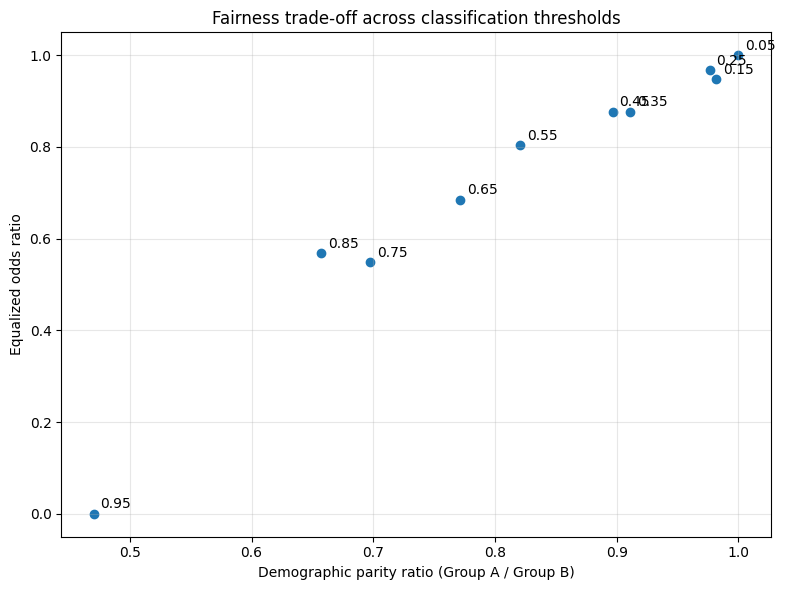

In [16]:
import matplotlib.pyplot as plt
plot_data = fairness_table.dropna(subset=["DP ratio", "EO ratio"])

plt.figure(figsize=(8, 6))
plt.scatter(plot_data["DP ratio"], plot_data["EO ratio"])

for _, row in plot_data.iterrows():
    plt.annotate(
        f'{row["Threshold"]:.2f}',
        (row["DP ratio"], row["EO ratio"]),
        xytext=(5, 4),
        textcoords="offset points"
    )

plt.xlabel("Demographic parity ratio (Group A / Group B)")
plt.ylabel("Equalized odds ratio")
plt.title("Fairness trade-off across classification thresholds")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
fairness_summary = fairness_table[
    ["Threshold", "DP ratio", "EO ratio", "PP ratio"]
].copy()

fairness_summary["DP distance from 1"] = (
    fairness_summary["DP ratio"] - 1
).abs()

fairness_summary["EO distance from 1"] = (
    fairness_summary["EO ratio"] - 1
).abs()

print("Thresholds with DP ratio closest to 1:")
display(
    fairness_summary.sort_values("DP distance from 1")
    .head(3).round(4)
)

print("Thresholds with EO ratio closest to 1:")
display(
    fairness_summary.sort_values("EO distance from 1")
    .head(3).round(4)
)

Thresholds with DP ratio closest to 1:


,Threshold,DP ratio,EO ratio,PP ratio,DP distance from 1,EO distance from 1
0,0.05,1.0000,1.0000,0.9108,0.0000,0.0000
1,0.15,0.9814,0.9480,0.9281,0.0186,0.0520
2,0.25,0.9764,0.9672,0.9240,0.0236,0.0328


Thresholds with EO ratio closest to 1:


,Threshold,DP ratio,EO ratio,PP ratio,DP distance from 1,EO distance from 1
0,0.05,1.0000,1.0000,0.9108,0.0000,0.0000
2,0.25,0.9764,0.9672,0.9240,0.0236,0.0328
1,0.15,0.9814,0.9480,0.9281,0.0186,0.0520
